In [39]:
import os
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from torch.cuda.amp import autocast, GradScaler
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight
import time
from tqdm import tqdm
from PIL import Image
import hashlib
import random
import platform

In [40]:
KAGGLE_INPUT_DIR = "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)"
TRAIN_DIR = os.path.join(KAGGLE_INPUT_DIR, "train")
VALID_DIR = os.path.join(KAGGLE_INPUT_DIR, "valid")
WORKING_DIR = "/kaggle/working"
LAST_CHECKPOINT = os.path.join(WORKING_DIR, "last.pth")
BEST_CHECKPOINT = os.path.join(WORKING_DIR, "best.pth")

EPOCHS = 5
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
NUM_WORKERS = os.cpu_count() or 2
PIN_MEMORY = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EARLY_STOPPING_PATIENCE = 3
MAX_GRAD_NORM = 1.0

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True

seed_everything()

print("-" * 50)
print(f"System: {platform.system()} {platform.release()}")
print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print("-" * 50)

--------------------------------------------------
System: Linux 6.12.90+
Python: 3.12.13
PyTorch: 2.10.0+cu128
Device: cuda
GPU: Tesla T4
--------------------------------------------------


In [41]:
print(TRAIN_DIR)
print(VALID_DIR)

print("Train Exists:", os.path.exists(TRAIN_DIR))
print("Valid Exists:", os.path.exists(VALID_DIR))

/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid
Train Exists: True
Valid Exists: True


Dataset Summary: Training Set Class Distribution
Total Classes: 38
Total Images: 70295
------------------------------


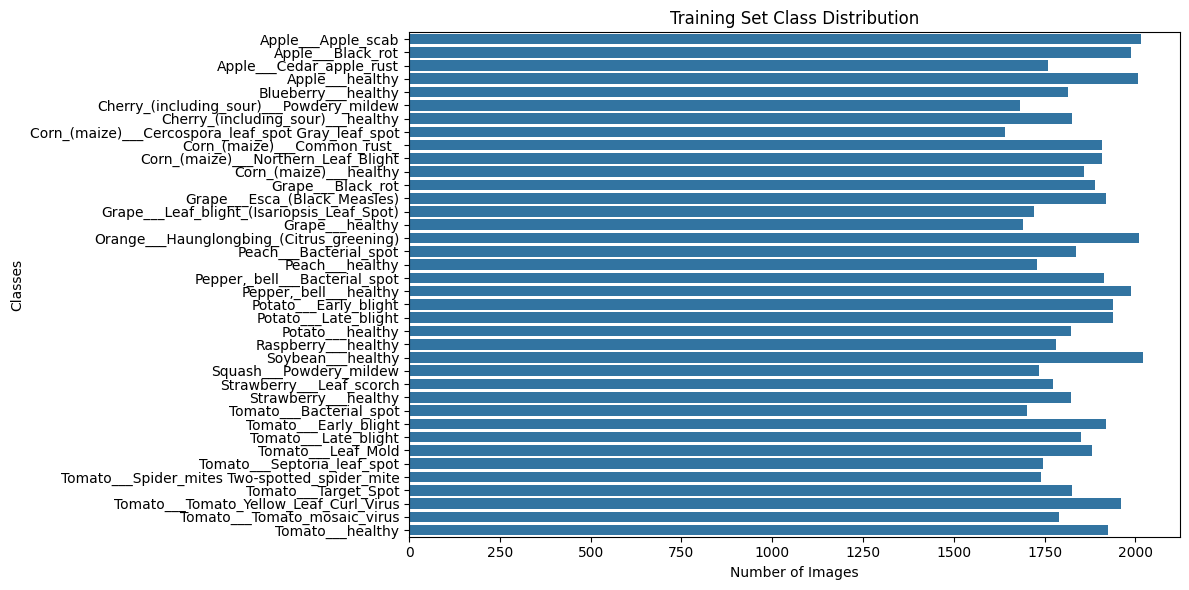

In [42]:
def plot_class_distribution(directory, title):
    class_names = sorted(os.listdir(directory))
    counts = [len(os.listdir(os.path.join(directory, c))) for c in class_names]
    
    print(f"Dataset Summary: {title}")
    print(f"Total Classes: {len(class_names)}")
    print(f"Total Images: {sum(counts)}")
    print("-" * 30)
    
    plt.figure(figsize=(12, 6))
    sns.barplot(x=counts, y=class_names, orient='h')
    plt.title(title)
    plt.xlabel("Number of Images")
    plt.ylabel("Classes")
    plt.tight_layout()
    plt.savefig(os.path.join(WORKING_DIR, f"{title.replace(' ', '_')}.png"))
    plt.show()

if os.path.exists(TRAIN_DIR):
    plot_class_distribution(TRAIN_DIR, "Training Set Class Distribution")

In [43]:
class HSVPlantDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []
        self.classes = sorted([d for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))])
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)}
        
        seen_hashes = set()
        corrupted_count = 0
        duplicate_count = 0
        
        for cls_name in self.classes:
            cls_dir = os.path.join(root_dir, cls_name)
            for img_name in os.listdir(cls_dir):
                img_path = os.path.join(cls_dir, img_name)
                try:
                    with Image.open(img_path) as img:
                        img.verify()
                        
                    with open(img_path, "rb") as f:
                        file_hash = hashlib.md5(f.read()).hexdigest()
                        
                    if file_hash in seen_hashes:
                        duplicate_count += 1
                        continue
                    seen_hashes.add(file_hash)
                    
                    self.image_paths.append(img_path)
                    self.labels.append(self.class_to_idx[cls_name])
                except (IOError, SyntaxError):
                    corrupted_count += 1
                    
        print(f"Loaded {len(self.image_paths)} valid images from {root_dir}.")
        if corrupted_count > 0 or duplicate_count > 0:
            print(f"Skipped {corrupted_count} corrupted and {duplicate_count} duplicate images.")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = cv2.imread(img_path)
        if img is None:
            img = np.zeros((224, 224, 3), dtype=np.uint8)
        else:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        label = self.labels[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

In [44]:
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((224, 224), antialias=True),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((224, 224), antialias=True),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

if os.path.exists(TRAIN_DIR) and os.path.exists(VALID_DIR):
    train_dataset = HSVPlantDataset(TRAIN_DIR, transform=train_transform)
    val_dataset = HSVPlantDataset(VALID_DIR, transform=val_transform)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, 
                              num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, 
                            num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=True)
    NUM_CLASSES = len(train_dataset.classes)
    CLASSES = train_dataset.classes
    
    class_weights = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(train_dataset.labels),
        y=train_dataset.labels
    )
    class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
else:
    NUM_CLASSES = 15
    CLASSES = [str(i) for i in range(15)]
    train_loader, val_loader = None, None
    class_weights_tensor = None

Loaded 70277 valid images from /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train.
Skipped 0 corrupted and 18 duplicate images.
Loaded 17570 valid images from /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid.
Skipped 0 corrupted and 2 duplicate images.


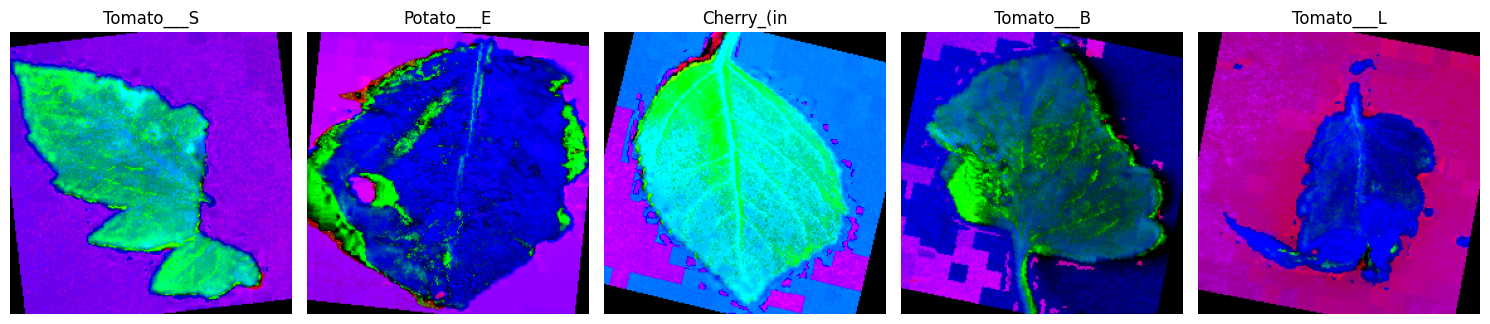

In [45]:
if train_loader is not None:
    images, labels = next(iter(train_loader))
    plt.figure(figsize=(15, 5))
    for i in range(5):
        plt.subplot(1, 5, i + 1)
        img_np = images[i].numpy().transpose(1, 2, 0)
        img_np = img_np * 0.5 + 0.5
        plt.imshow(np.clip(img_np, 0, 1))
        plt.title(CLASSES[labels[i].item()][:10])
        plt.axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(WORKING_DIR, "hsv_samples.png"))
    plt.show()

In [46]:

model = mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.last_channel, NUM_CLASSES)
model = model.to(DEVICE)

In [47]:
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = GradScaler()

/tmp/ipykernel_59/1476145366.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


In [48]:

start_epoch = 0
best_val_acc = 0.0
total_training_time = 0.0
epochs_no_improve = 0
train_losses, val_losses, train_accs, val_accs = [], [], [], []

if os.path.exists(LAST_CHECKPOINT):
    checkpoint = torch.load(LAST_CHECKPOINT, map_location=DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    scaler.load_state_dict(checkpoint['scaler_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    best_val_acc = checkpoint['best_val_acc']
    total_training_time = checkpoint.get('total_training_time', 0.0)
    train_losses = checkpoint['train_losses']
    val_losses = checkpoint['val_losses']
    train_accs = checkpoint['train_accs']
    val_accs = checkpoint['val_accs']
    epochs_no_improve = checkpoint.get('epochs_no_improve', 0)

if os.path.exists(BEST_CHECKPOINT) and start_epoch == 0:
    checkpoint = torch.load(BEST_CHECKPOINT, map_location=DEVICE)
    best_val_acc = checkpoint['val_acc']

In [49]:

if train_loader is not None and val_loader is not None:
    for epoch in range(start_epoch, EPOCHS):
        epoch_start_time = time.time()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        
        custom_bar_format = "{desc} {percentage:3.0f}%|{bar}| {n_fmt}/{total_fmt} [Elapsed: {elapsed} < ETA: {remaining}, {rate_fmt}] {postfix}"
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]", unit="batch", leave=False, dynamic_ncols=True, bar_format=custom_bar_format)
        for images, labels in train_pbar:
            batch_start_time = time.time()
            images, labels = images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            
            with autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            scaler.step(optimizer)
            scaler.update()
            
            batch_size = images.size(0)
            running_loss += loss.item() * batch_size
            _, predicted = torch.max(outputs, 1)
            total += batch_size
            correct += (predicted == labels).sum().item()
            
            live_loss = running_loss / total
            live_acc = correct / total
            current_lr = optimizer.param_groups[0]['lr']
            vram_usage = torch.cuda.memory_reserved(DEVICE) / (1024**3) if torch.cuda.is_available() else 0.0
            batch_time = time.time() - batch_start_time
            
            train_pbar.set_postfix(
                Loss=f"{live_loss:.4f}",
                Acc=f"{live_acc:.4f}",
                LR=f"{current_lr:.2e}",
                BestVal=f"{best_val_acc:.4f}",
                VRAM=f"{vram_usage:.1f}GB",
                BatchTime=f"{batch_time:.3f}s"
            )
            
        epoch_train_loss = running_loss / total
        epoch_train_acc = correct / total
        train_losses.append(epoch_train_loss)
        train_accs.append(epoch_train_acc)
        
        model.eval()
        running_val_loss, val_correct, val_total = 0.0, 0, 0
        all_val_preds, all_val_labels = [], []
        
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]", unit="batch", leave=False, dynamic_ncols=True, bar_format=custom_bar_format)
        with torch.no_grad():
            for images, labels in val_pbar:
                images, labels = images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
                with autocast():
                    outputs = model(images)
                    loss = criterion(outputs, labels)
                    
                batch_size = images.size(0)
                running_val_loss += loss.item() * batch_size
                _, predicted = torch.max(outputs, 1)
                val_total += batch_size
                val_correct += (predicted == labels).sum().item()
                
                all_val_preds.extend(predicted.cpu().numpy())
                all_val_labels.extend(labels.cpu().numpy())
                
                live_val_loss = running_val_loss / val_total
                live_val_acc = val_correct / val_total
                val_pbar.set_postfix(Loss=f"{live_val_loss:.4f}", Acc=f"{live_val_acc:.4f}")
                
        epoch_val_loss = running_val_loss / val_total
        epoch_val_acc = val_correct / val_total
        val_losses.append(epoch_val_loss)
        val_accs.append(epoch_val_acc)
        
        precision, recall, f1, _ = precision_recall_fscore_support(
            all_val_labels, all_val_preds, average='macro', zero_division=0
        )
        
        scheduler.step()
        epoch_time = time.time() - epoch_start_time
        total_training_time += epoch_time
        
        is_best = epoch_val_acc > best_val_acc
        if is_best:
            best_val_acc = epoch_val_acc
            epochs_no_improve = 0
            best_tmp = BEST_CHECKPOINT + ".tmp"
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'val_acc': epoch_val_acc
            }, best_tmp)
            os.replace(best_tmp, BEST_CHECKPOINT)
        else:
            epochs_no_improve += 1
            
        last_tmp = LAST_CHECKPOINT + ".tmp"
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'scaler_state_dict': scaler.state_dict(),
            'best_val_acc': best_val_acc,
            'total_training_time': total_training_time,
            'train_losses': train_losses,
            'val_losses': val_losses,
            'train_accs': train_accs,
            'val_accs': val_accs,
            'epochs_no_improve': epochs_no_improve
        }, last_tmp)
        os.replace(last_tmp, LAST_CHECKPOINT)
        
        chkp_status = "best.pth, last.pth" if is_best else "last.pth"
        
        print(f"Epoch {epoch+1}/{EPOCHS} Summary:")
        print("-" * 80)
        print(f"Train Loss: {epoch_train_loss:.4f}     | Val Loss: {epoch_val_loss:.4f}     | Epoch Time: {epoch_time:.1f}s")
        print(f"Train Acc:  {epoch_train_acc*100:.2f}%     | Val Acc:  {epoch_val_acc*100:.2f}%     | Total Time: {total_training_time:.1f}s")
        print(f"Precision:  {precision:.4f}     | Recall:   {recall:.4f}     | F1 Score:   {f1:.4f}")
        print(f"LR:         {current_lr:.2e} | Best Val: {best_val_acc*100:.2f}%     | Saved:      {chkp_status}")
        print("-" * 80)
        
        if epochs_no_improve >= EARLY_STOPPING_PATIENCE:
            print(f"Early stopping triggered after {epoch+1} epochs.")
            break

Epoch 1/5 [Train]   0%|          | 0/550 [Elapsed: 00:00 < ETA: ?, ?batch/s] /tmp/ipykernel_59/2263222294.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch 1/5 [Val]   0%|          | 0/138 [Elapsed: 00:00 < ETA: ?, ?batch/s]                                                                                                  /tmp/ipykernel_59/2263222294.py:58: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 1/5 Summary:
--------------------------------------------------------------------------------
Train Loss: 0.3019     | Val Loss: 0.1189     | Epoch Time: 617.6s
Train Acc:  91.13%     | Val Acc:  96.11%     | Total Time: 617.6s
Precision:  0.9644     | Recall:   0.9603     | F1 Score:   0.9602
LR:         1.00e-03 | Best Val: 96.11%     | Saved:      best.pth, last.pth
--------------------------------------------------------------------------------


Epoch 2/5 [Train]   0%|          | 0/550 [Elapsed: 00:00 < ETA: ?, ?batch/s] /tmp/ipykernel_59/2263222294.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch 2/5 [Val]   0%|          | 0/138 [Elapsed: 00:00 < ETA: ?, ?batch/s]                                                                                                 /tmp/ipykernel_59/2263222294.py:58: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 2/5 Summary:
--------------------------------------------------------------------------------
Train Loss: 0.0825     | Val Loss: 0.0582     | Epoch Time: 547.1s
Train Acc:  97.31%     | Val Acc:  98.13%     | Total Time: 1164.6s
Precision:  0.9814     | Recall:   0.9812     | F1 Score:   0.9811
LR:         9.05e-04 | Best Val: 98.13%     | Saved:      best.pth, last.pth
--------------------------------------------------------------------------------


Epoch 3/5 [Train]   0%|          | 0/550 [Elapsed: 00:00 < ETA: ?, ?batch/s] /tmp/ipykernel_59/2263222294.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch 3/5 [Val]   0%|          | 0/138 [Elapsed: 00:00 < ETA: ?, ?batch/s]                                                                                                 /tmp/ipykernel_59/2263222294.py:58: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 3/5 Summary:
--------------------------------------------------------------------------------
Train Loss: 0.0407     | Val Loss: 0.0339     | Epoch Time: 546.8s
Train Acc:  98.65%     | Val Acc:  98.83%     | Total Time: 1711.4s
Precision:  0.9884     | Recall:   0.9881     | F1 Score:   0.9881
LR:         6.55e-04 | Best Val: 98.83%     | Saved:      best.pth, last.pth
--------------------------------------------------------------------------------


Epoch 4/5 [Train]   0%|          | 0/550 [Elapsed: 00:00 < ETA: ?, ?batch/s] /tmp/ipykernel_59/2263222294.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch 4/5 [Val]   0%|          | 0/138 [Elapsed: 00:00 < ETA: ?, ?batch/s]                                                                                                 /tmp/ipykernel_59/2263222294.py:58: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 4/5 Summary:
--------------------------------------------------------------------------------
Train Loss: 0.0196     | Val Loss: 0.0147     | Epoch Time: 544.9s
Train Acc:  99.32%     | Val Acc:  99.49%     | Total Time: 2256.3s
Precision:  0.9947     | Recall:   0.9948     | F1 Score:   0.9948
LR:         3.45e-04 | Best Val: 99.49%     | Saved:      best.pth, last.pth
--------------------------------------------------------------------------------


Epoch 5/5 [Train]   0%|          | 0/550 [Elapsed: 00:00 < ETA: ?, ?batch/s] /tmp/ipykernel_59/2263222294.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch 5/5 [Val]   0%|          | 0/138 [Elapsed: 00:00 < ETA: ?, ?batch/s]                                                                                                 /tmp/ipykernel_59/2263222294.py:58: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
                                                                                                              

Epoch 5/5 Summary:
--------------------------------------------------------------------------------
Train Loss: 0.0104     | Val Loss: 0.0100     | Epoch Time: 552.2s
Train Acc:  99.69%     | Val Acc:  99.68%     | Total Time: 2808.5s
Precision:  0.9968     | Recall:   0.9966     | F1 Score:   0.9967
LR:         9.55e-05 | Best Val: 99.68%     | Saved:      best.pth, last.pth
--------------------------------------------------------------------------------


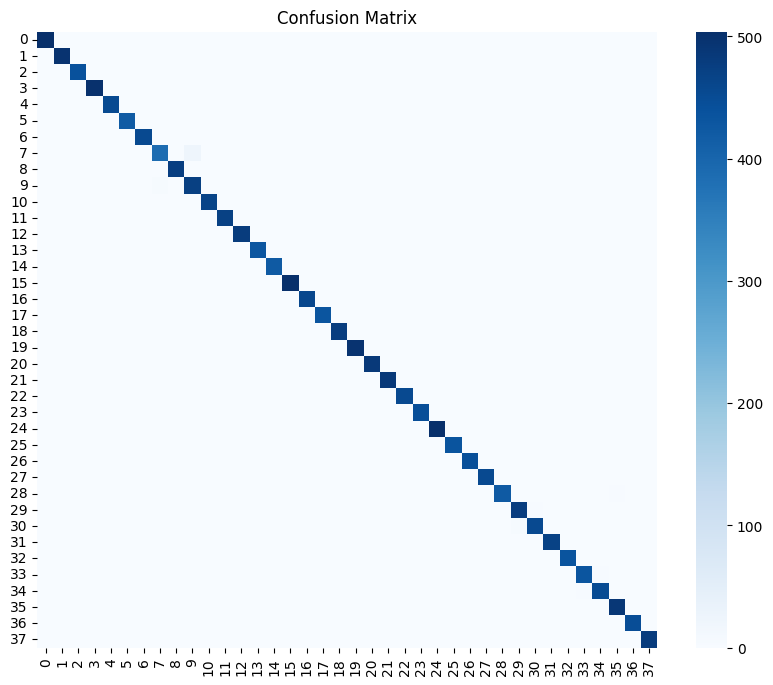

In [50]:

if val_loader is not None:
    model.load_state_dict(torch.load(BEST_CHECKPOINT)['model_state_dict'])
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE, non_blocking=True)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())
            
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=False, cmap='Blues')
    plt.title("Confusion Matrix")
    plt.savefig(os.path.join(WORKING_DIR, "confusion_matrix.png"))
    plt.show()
    
    report = classification_report(all_labels, all_preds, target_names=CLASSES)
    with open(os.path.join(WORKING_DIR, "classification_report.txt"), "w") as f:
        f.write(report)

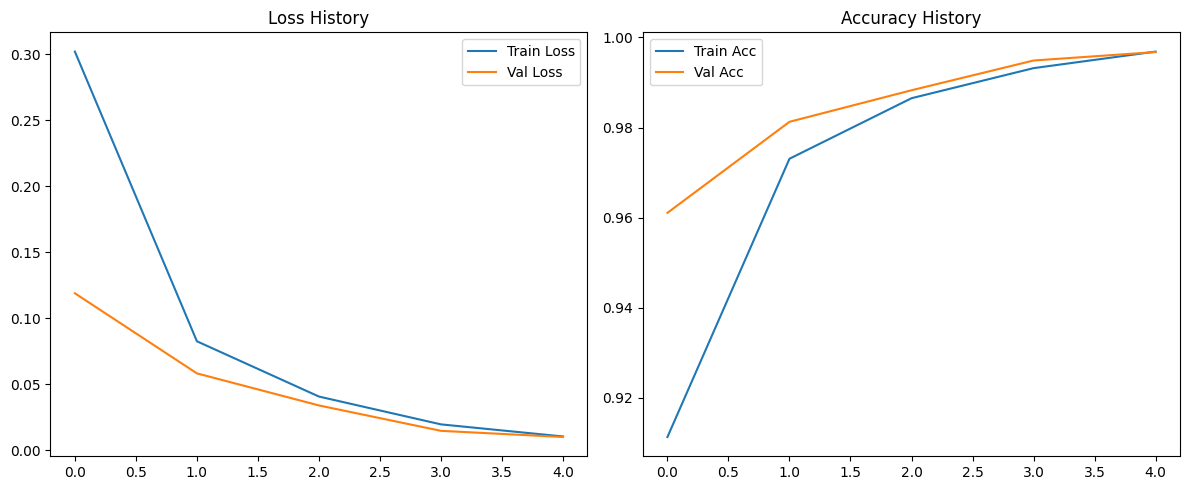

In [51]:

if train_loader is not None:
    epochs_range = range(len(train_losses))
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, train_losses, label='Train Loss')
    plt.plot(epochs_range, val_losses, label='Val Loss')
    plt.legend()
    plt.title('Loss History')
    
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, train_accs, label='Train Acc')
    plt.plot(epochs_range, val_accs, label='Val Acc')
    plt.legend()
    plt.title('Accuracy History')
    
    plt.tight_layout()
    plt.savefig(os.path.join(WORKING_DIR, "training_history.png"))
    plt.show()

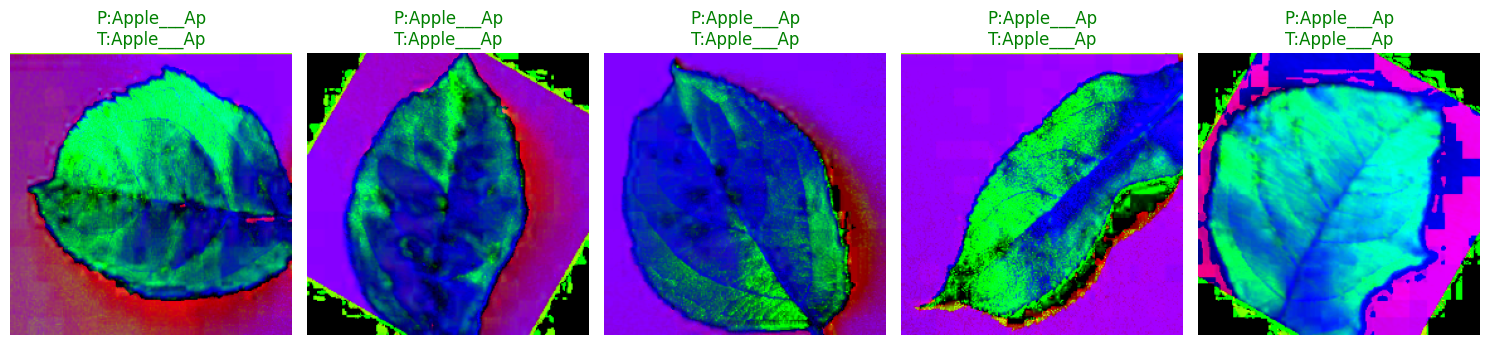

In [52]:

if val_loader is not None:
    images, labels = next(iter(val_loader))
    images_device = images.to(DEVICE)
    model.eval()
    with torch.no_grad():
        outputs = model(images_device)
        _, preds = torch.max(outputs, 1)
        
    plt.figure(figsize=(15, 5))
    for i in range(5):
        plt.subplot(1, 5, i + 1)
        img_np = images[i].numpy().transpose(1, 2, 0)
        img_np = img_np * 0.5 + 0.5
        plt.imshow(np.clip(img_np, 0, 1))
        pred_label = CLASSES[preds[i].item()][:10]
        true_label = CLASSES[labels[i].item()][:10]
        plt.title(f"P:{pred_label}\nT:{true_label}", color="green" if pred_label==true_label else "red")
        plt.axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(WORKING_DIR, "predictions.png"))
    plt.show()
    
    exported_model_path = os.path.join(WORKING_DIR, "mobilenetv2_pest_detection.pt")
    torch.save(model, exported_model_path)

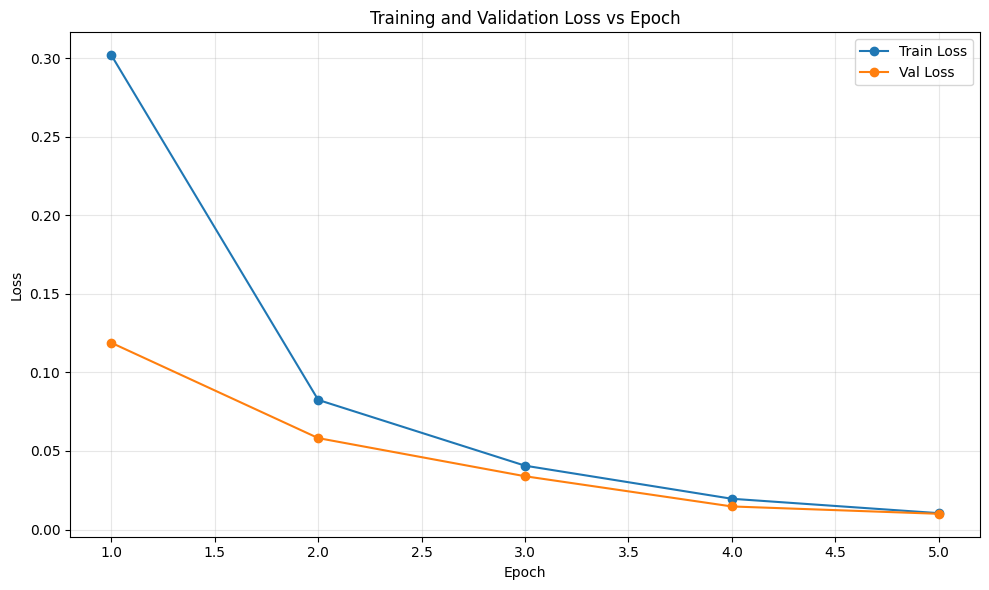

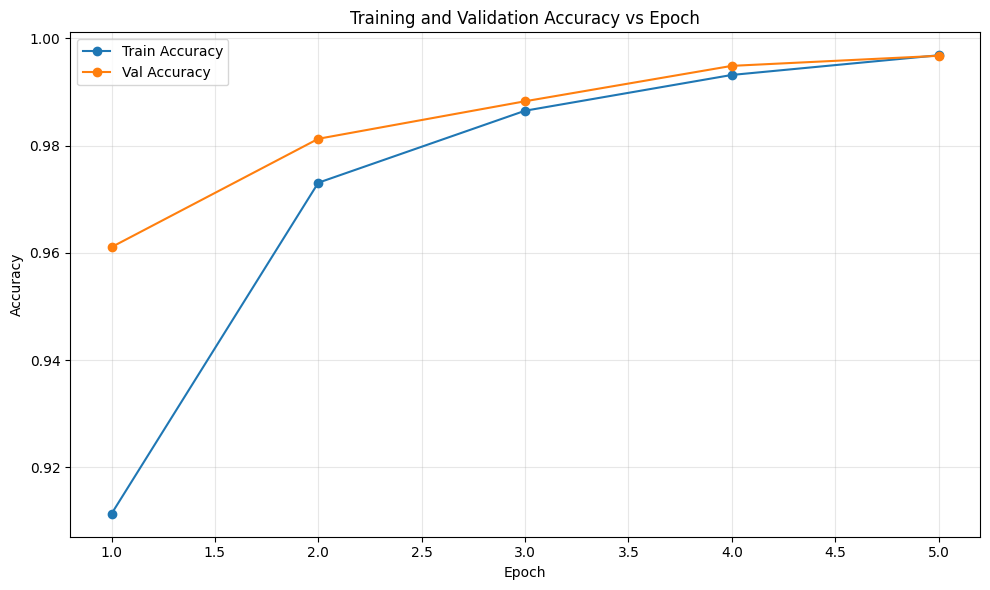

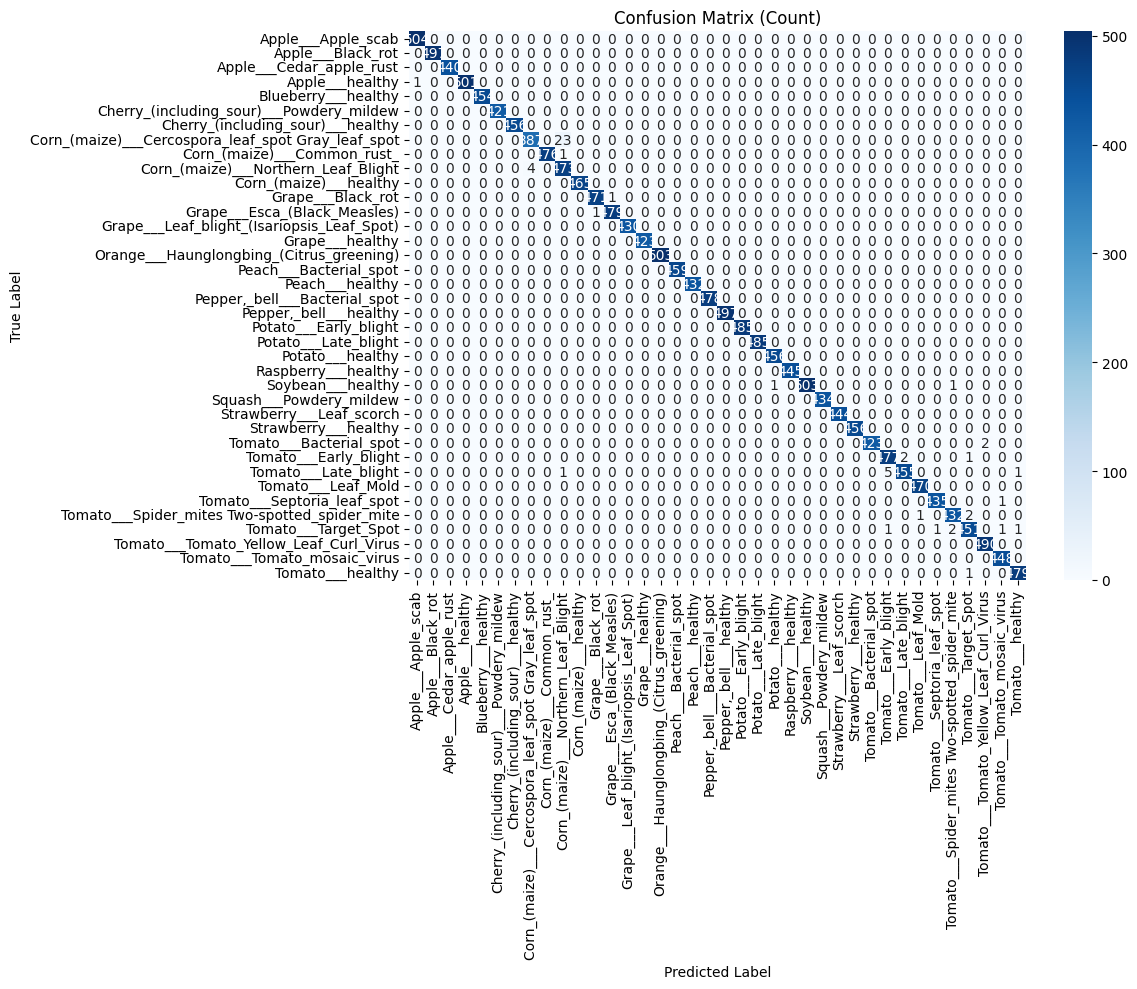

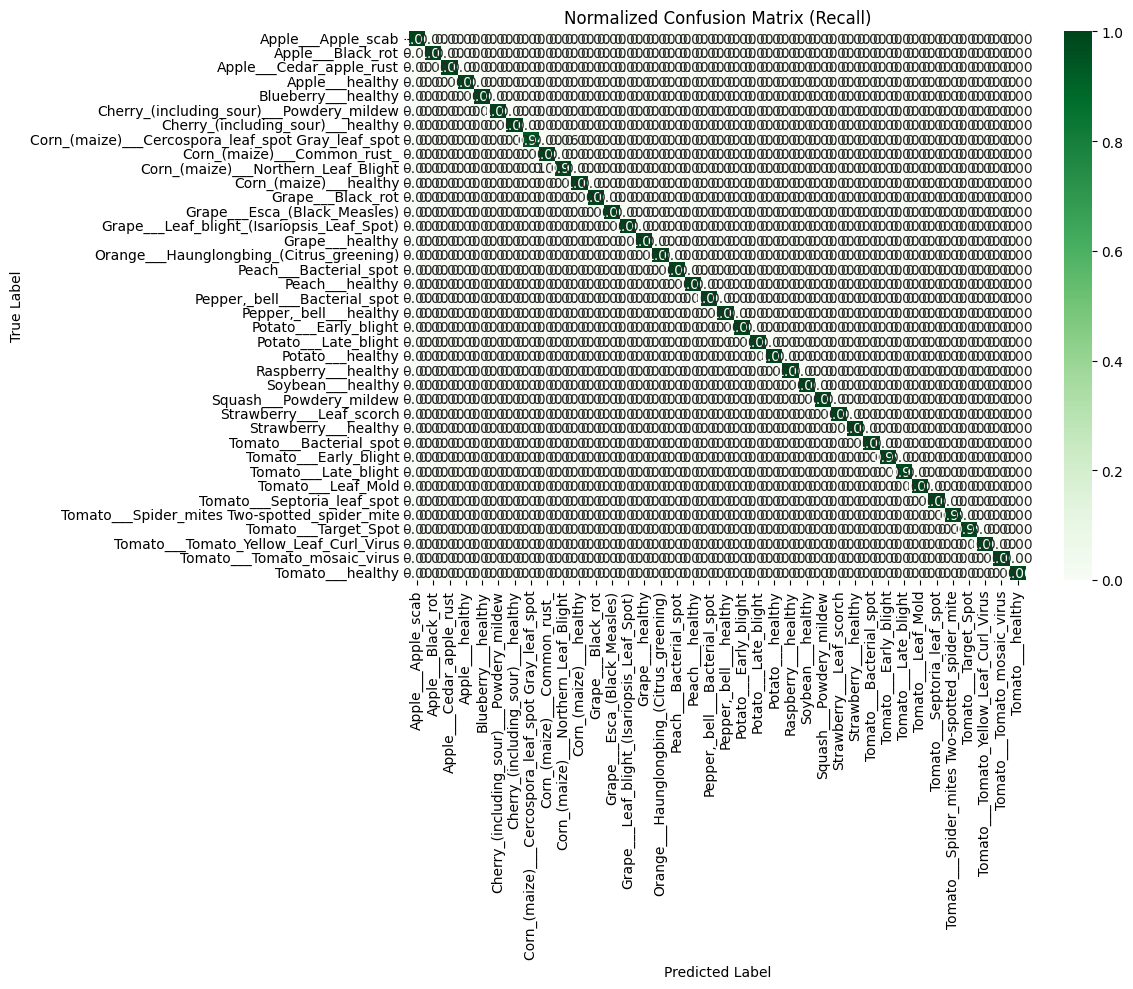

/tmp/ipykernel_59/3946124055.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=data, y=CLASSES, orient='h', palette='viridis')


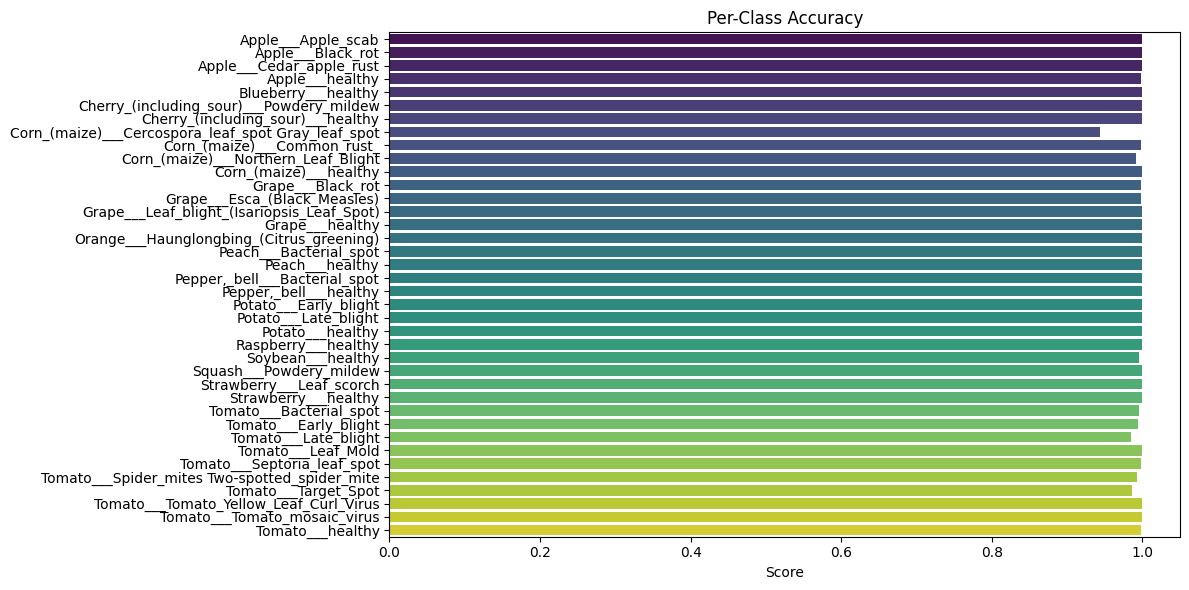

/tmp/ipykernel_59/3946124055.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=data, y=CLASSES, orient='h', palette='viridis')


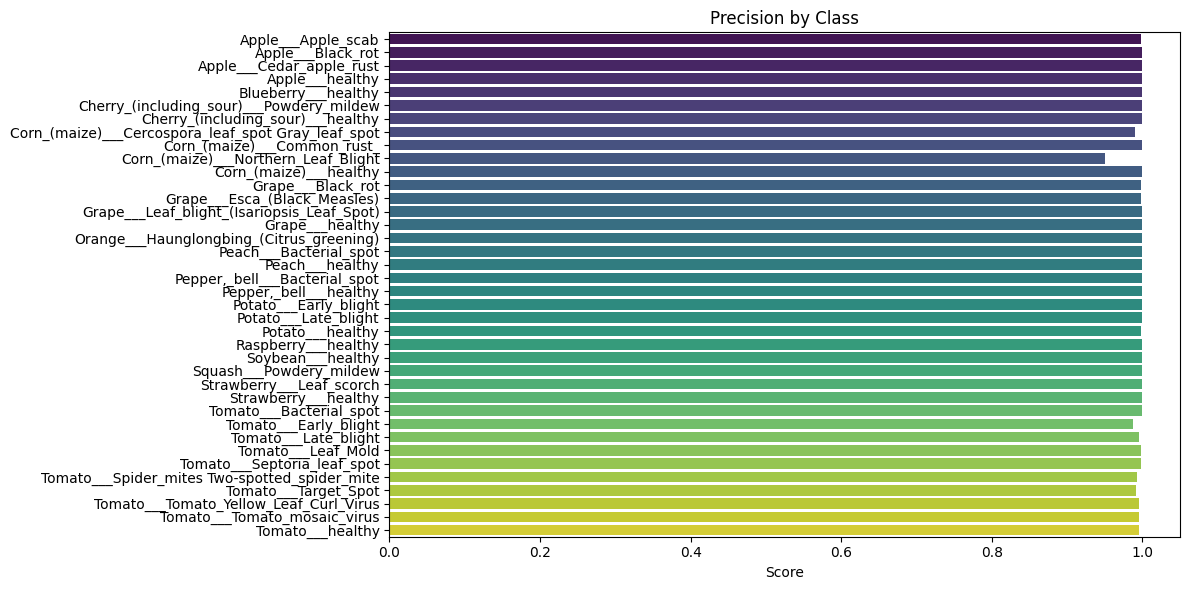

/tmp/ipykernel_59/3946124055.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=data, y=CLASSES, orient='h', palette='viridis')


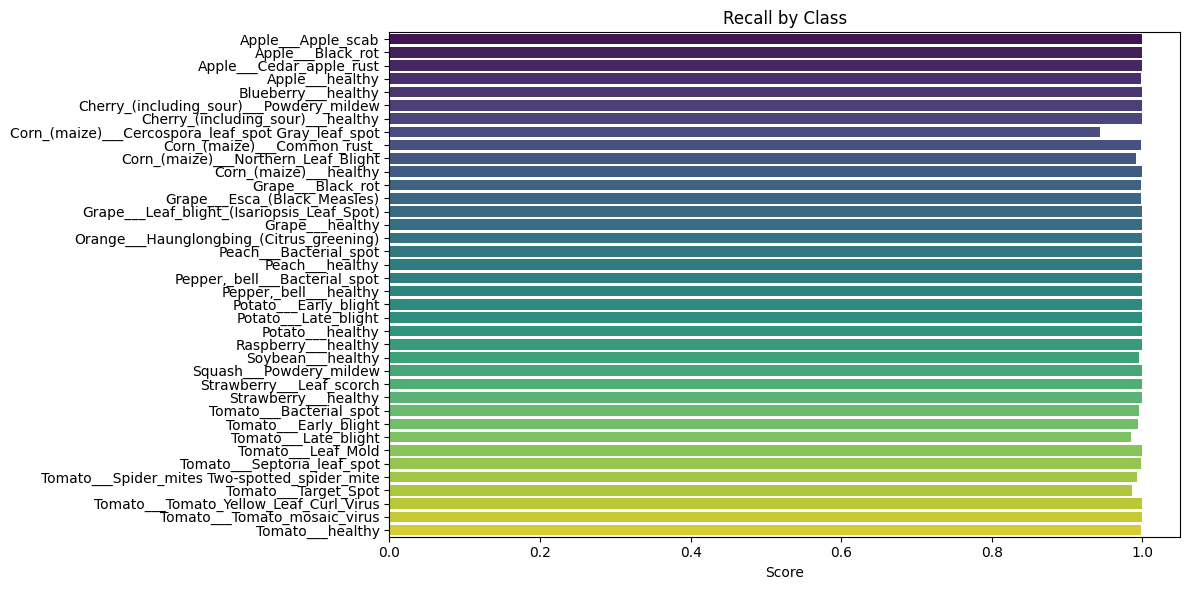

/tmp/ipykernel_59/3946124055.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=data, y=CLASSES, orient='h', palette='viridis')


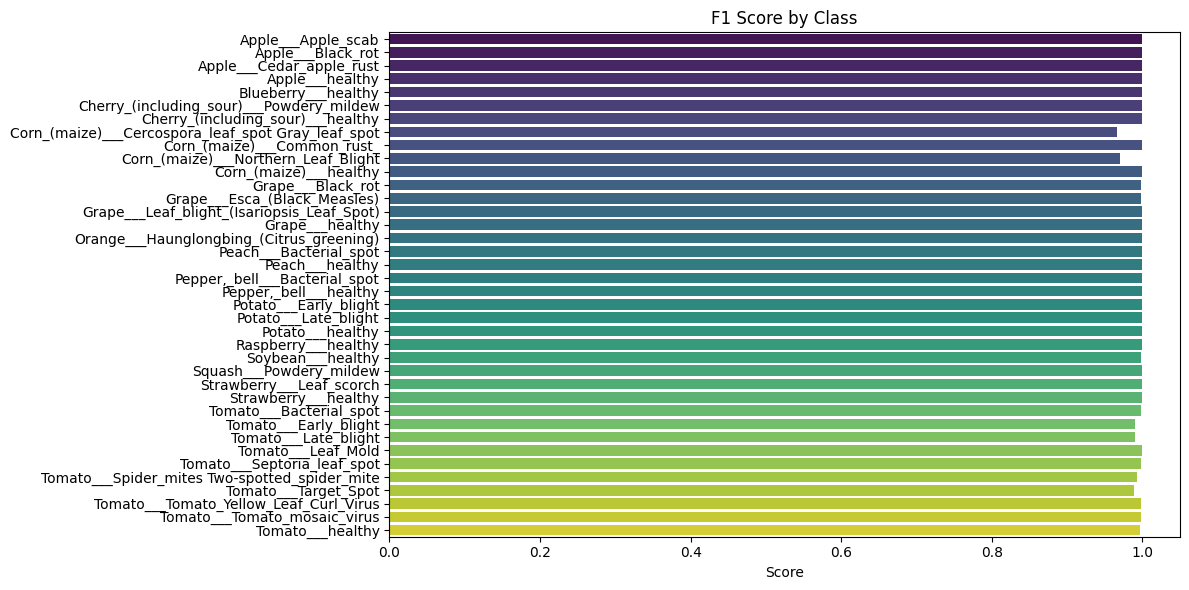

/tmp/ipykernel_59/3946124055.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=support_c, y=CLASSES, orient='h', palette='magma')


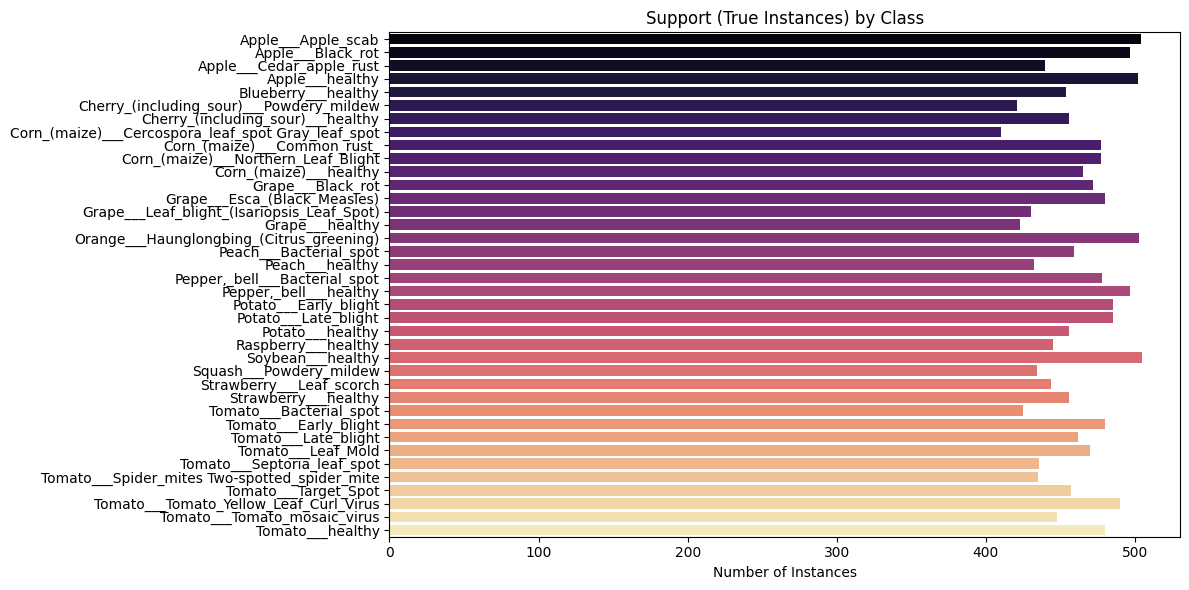

/tmp/ipykernel_59/3946124055.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pred_counts, y=CLASSES, orient='h', palette='coolwarm')


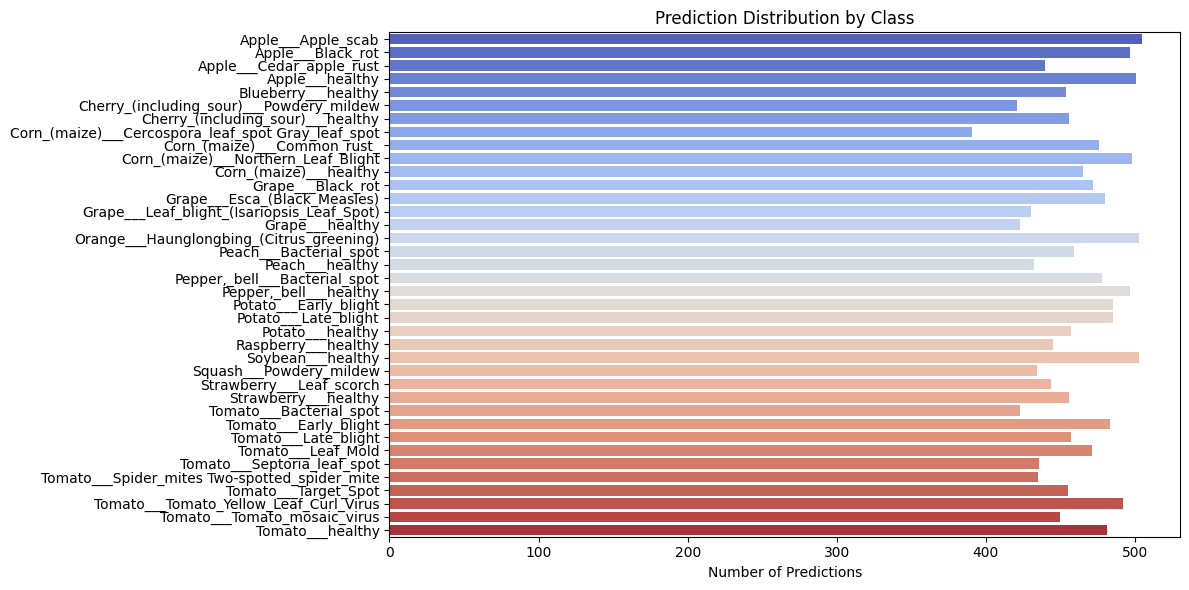

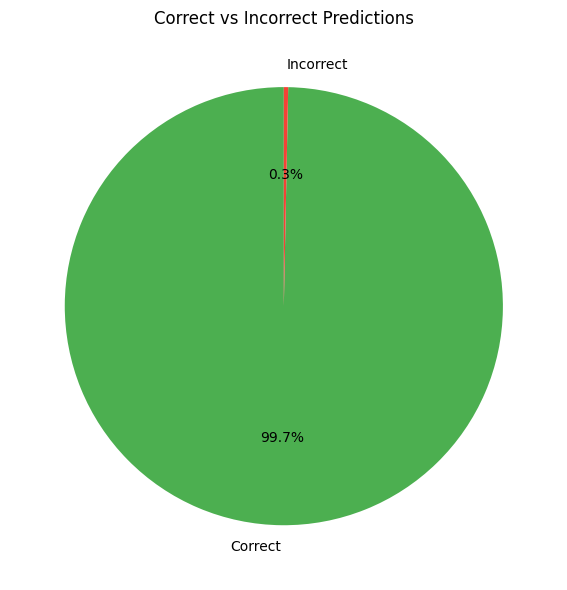

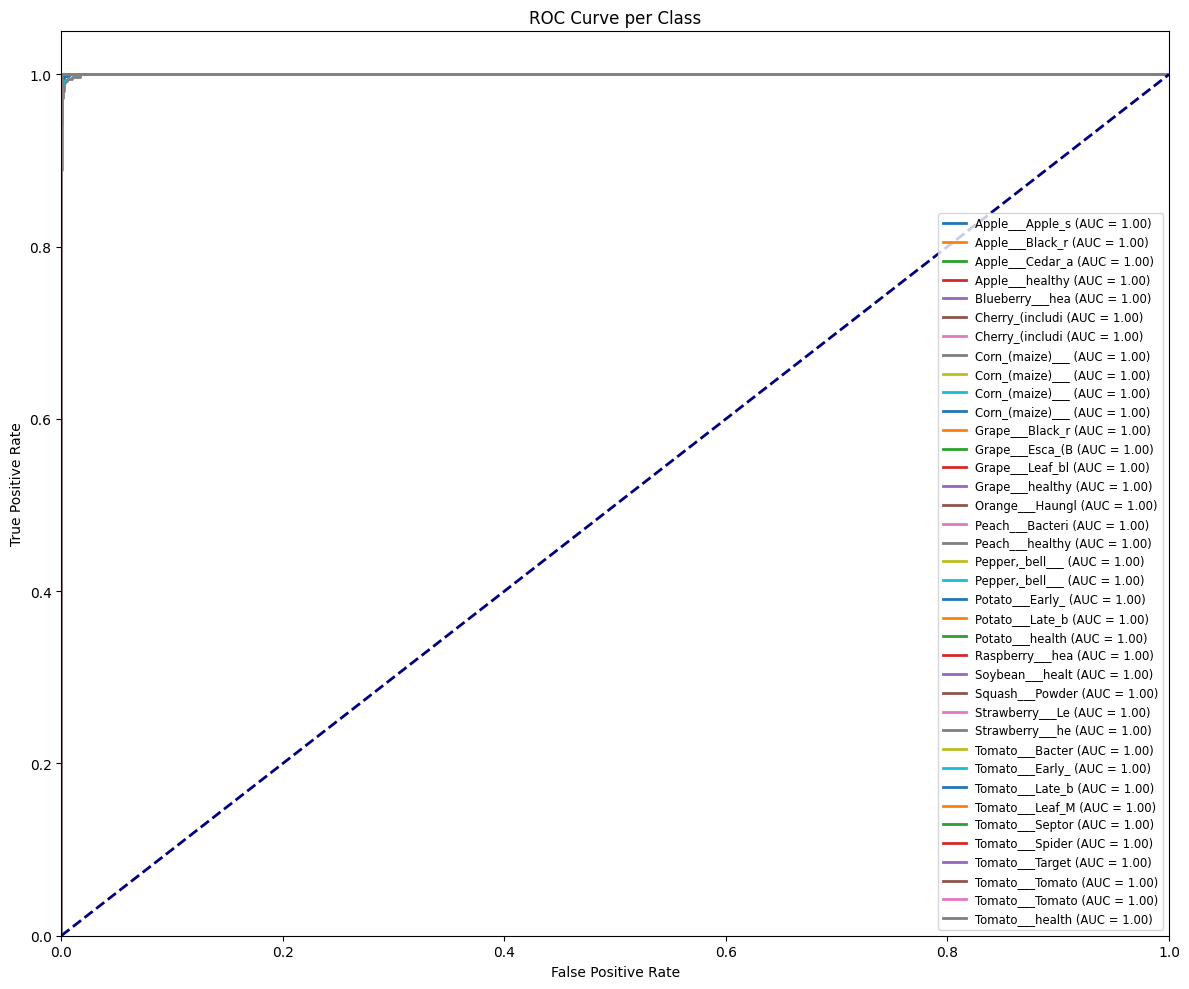

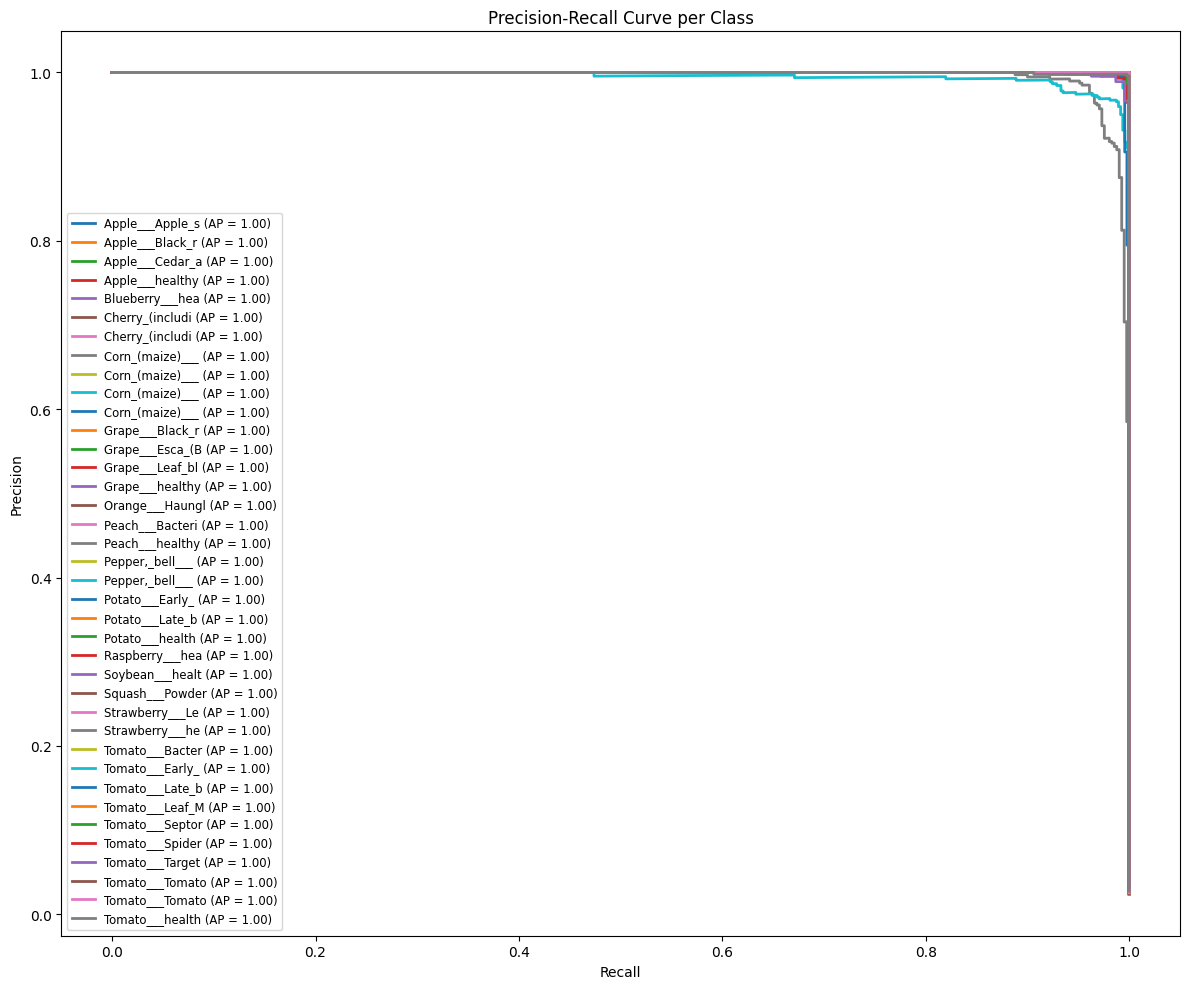

In [53]:

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import datetime
import zipfile
import glob

if val_loader is not None and os.path.exists(BEST_CHECKPOINT):
    model.load_state_dict(torch.load(BEST_CHECKPOINT, map_location=DEVICE)['model_state_dict'])
    model.eval()
    all_labels_eval = []
    all_preds_eval = []
    all_probs_eval = []
    
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE, non_blocking=True)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            
            all_labels_eval.extend(labels.cpu().numpy())
            all_preds_eval.extend(preds.cpu().numpy())
            all_probs_eval.extend(probs.cpu().numpy())
            
    all_labels_eval = np.array(all_labels_eval)
    all_preds_eval = np.array(all_preds_eval)
    all_probs_eval = np.array(all_probs_eval)
    
    def save_fig(filename):
        plt.tight_layout()
        plt.savefig(os.path.join(WORKING_DIR, filename), dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    if os.path.exists(LAST_CHECKPOINT):
        chkpt = torch.load(LAST_CHECKPOINT, map_location='cpu')
        t_loss, v_loss = chkpt['train_losses'], chkpt['val_losses']
        t_acc, v_acc = chkpt['train_accs'], chkpt['val_accs']
        epochs_range = range(1, len(t_loss) + 1)
        
        plt.figure(figsize=(10, 6))
        plt.plot(epochs_range, t_loss, marker='o', label='Train Loss')
        plt.plot(epochs_range, v_loss, marker='o', label='Val Loss')
        plt.title('Training and Validation Loss vs Epoch')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, alpha=0.3)
        save_fig('loss_curve.png')
        
        plt.figure(figsize=(10, 6))
        plt.plot(epochs_range, t_acc, marker='o', label='Train Accuracy')
        plt.plot(epochs_range, v_acc, marker='o', label='Val Accuracy')
        plt.title('Training and Validation Accuracy vs Epoch')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.grid(True, alpha=0.3)
        save_fig('accuracy_curve.png')

    cm = confusion_matrix(all_labels_eval, all_preds_eval)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
    plt.title('Confusion Matrix (Count)')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    save_fig('confusion_matrix_normal.png')

    cm_norm = confusion_matrix(all_labels_eval, all_preds_eval, normalize='true')
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens', xticklabels=CLASSES, yticklabels=CLASSES)
    plt.title('Normalized Confusion Matrix (Recall)')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    save_fig('confusion_matrix_normalized.png')

    precision_c, recall_c, f1_c, support_c = precision_recall_fscore_support(all_labels_eval, all_preds_eval, zero_division=0)
    per_class_acc = cm.diagonal() / cm.sum(axis=1)

    metrics_dict = {
        'per_class_accuracy.png': ('Per-Class Accuracy', per_class_acc),
        'precision_by_class.png': ('Precision by Class', precision_c),
        'recall_by_class.png': ('Recall by Class', recall_c),
        'f1_score_by_class.png': ('F1 Score by Class', f1_c)
    }

    for filename, (title, data) in metrics_dict.items():
        plt.figure(figsize=(12, 6))
        sns.barplot(x=data, y=CLASSES, orient='h', palette='viridis')
        plt.title(title)
        plt.xlabel('Score')
        plt.xlim(0, 1.05)
        save_fig(filename)

    plt.figure(figsize=(12, 6))
    sns.barplot(x=support_c, y=CLASSES, orient='h', palette='magma')
    plt.title('Support (True Instances) by Class')
    plt.xlabel('Number of Instances')
    save_fig('support_by_class.png')

    pred_counts = np.bincount(all_preds_eval, minlength=NUM_CLASSES)
    plt.figure(figsize=(12, 6))
    sns.barplot(x=pred_counts, y=CLASSES, orient='h', palette='coolwarm')
    plt.title('Prediction Distribution by Class')
    plt.xlabel('Number of Predictions')
    save_fig('prediction_distribution.png')

    correct_cnt = (all_labels_eval == all_preds_eval).sum()
    incorrect_cnt = len(all_labels_eval) - correct_cnt
    plt.figure(figsize=(6, 6))
    plt.pie([correct_cnt, incorrect_cnt], labels=['Correct', 'Incorrect'], autopct='%1.1f%%', colors=['#4CAF50', '#F44336'], startangle=90)
    plt.title('Correct vs Incorrect Predictions')
    save_fig('correct_vs_incorrect.png')

    y_bin = label_binarize(all_labels_eval, classes=range(NUM_CLASSES))
    plt.figure(figsize=(12, 10))
    for i in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs_eval[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f'{CLASSES[i][:15]} (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve per Class')
    plt.legend(loc="lower right", fontsize='small')
    save_fig('roc_curve.png')

    plt.figure(figsize=(12, 10))
    for i in range(NUM_CLASSES):
        prec, rec, _ = precision_recall_curve(y_bin[:, i], all_probs_eval[:, i])
        ap = average_precision_score(y_bin[:, i], all_probs_eval[:, i])
        plt.plot(rec, prec, lw=2, label=f'{CLASSES[i][:15]} (AP = {ap:.2f})')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve per Class')
    plt.legend(loc="lower left", fontsize='small')
    save_fig('precision_recall_curve.png')

In [54]:
if val_loader is not None and os.path.exists(BEST_CHECKPOINT):
    rep_dict = classification_report(all_labels_eval, all_preds_eval, target_names=CLASSES, output_dict=True, zero_division=0)
    
    chkpt_last = torch.load(LAST_CHECKPOINT, map_location='cpu')
    chkpt_best = torch.load(BEST_CHECKPOINT, map_location='cpu')
    
    best_epoch = chkpt_best.get('epoch', 0) + 1
    total_time = chkpt_last.get('total_training_time', 0)
    
    report_content = f"""==================================================
FINAL MODEL TRAINING REPORT
==================================================
Project Name         : Hybrid Remote Sensing Crop Risk Evaluation
Model Name           : MobileNetV2 (RGB to HSV Pipeline)
Dataset Name         : PlantVillage Dataset (Augmented)
Number of Classes    : {NUM_CLASSES}
Training Images      : {len(train_dataset)}
Validation Images    : {len(val_dataset)}
Epochs Completed     : {chkpt_last.get('epoch', 0) + 1}
Batch Size           : {BATCH_SIZE}
Learning Rate        : {LEARNING_RATE}
Optimizer            : AdamW
Scheduler            : CosineAnnealingLR
Loss Function        : CrossEntropyLoss (Balanced Class Weights)
GPU Used             : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}
Total Training Time  : {total_time / 60:.2f} minutes
Export Date & Time   : {datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")}
Training Status      : Completed Successfully

--- OVERALL PERFORMANCE (BEST EPOCH: {best_epoch}) ---
Best Validation Acc  : {chkpt_last.get('best_val_acc', 0) * 100:.2f}%
Macro Precision      : {rep_dict['macro avg']['precision']:.4f}
Macro Recall         : {rep_dict['macro avg']['recall']:.4f}
Macro F1 Score       : {rep_dict['macro avg']['f1-score']:.4f}
Weighted Precision   : {rep_dict['weighted avg']['precision']:.4f}
Weighted Recall      : {rep_dict['weighted avg']['recall']:.4f}
Weighted F1 Score    : {rep_dict['weighted avg']['f1-score']:.4f}

--- ARTIFACTS GENERATED ---
Best Checkpoint      : best.pth
Last Checkpoint      : last.pth
Exported Model       : mobilenetv2_pest_detection.pt
==================================================
"""
    report_path = os.path.join(WORKING_DIR, "training_report.txt")
    with open(report_path, "w") as f:
        f.write(report_content)

In [55]:
requirements_content = """torch>=2.0.0
torchvision>=0.15.0
opencv-python>=4.7.0
matplotlib>=3.7.0
seaborn>=0.12.0
numpy>=1.23.0
scikit-learn>=1.2.0
tqdm>=4.65.0
Pillow>=9.5.0
"""
req_path = os.path.join(WORKING_DIR, "requirements.txt")
with open(req_path, "w") as f:
    f.write(requirements_content)

In [56]:

zip_filename = os.path.join(WORKING_DIR, "mobilenetv2_pest_detection_results.zip")
files_to_zip = glob.glob(os.path.join(WORKING_DIR, "*.png"))
files_to_zip.extend([
    os.path.join(WORKING_DIR, "best.pth"),
    os.path.join(WORKING_DIR, "last.pth"),
    os.path.join(WORKING_DIR, "mobilenetv2_pest_detection.pt"),
    os.path.join(WORKING_DIR, "classification_report.txt"),
    os.path.join(WORKING_DIR, "training_report.txt"),
    os.path.join(WORKING_DIR, "requirements.txt")
])

with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in files_to_zip:
        if os.path.exists(file):
            zipf.write(file, os.path.basename(file))
            
print(f"All artifacts successfully exported to: {zip_filename}")

All artifacts successfully exported to: /kaggle/working/mobilenetv2_pest_detection_results.zip
